# 03 · The nucleophile elbow
**Question.** Can the catalytic nucleophile be located from backbone geometry rather than a sequence motif?
**Definition (see `src/abhd/config.py`).** Ser/Cys/Thr/Asp with φ ∈ [30°,90°], ψ ∈ [−170°,−80°] (strained γ-like turn at the β5→αC
elbow), preceded by a β residue, followed by a helical residue, pLDDT ≥ 70 at Cα.
**Comparison.** The motif regex from the original notebook, applied to the 5-mer centred on the candidate: `(G.|.G)[SCT](G.|.G)` or `.PS..`.

In [1]:
import sys, warnings; warnings.filterwarnings("ignore")
from pathlib import Path; sys.path.insert(0, str(Path.cwd().parent / "src"))   # notebooks/ -> ../src
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from abhd import config as C, data as D, plots as P
pd.set_option("display.width", 160, "display.max_colwidth", 60)
meta = D.load_entries()

el = D.load_elbow(); summ = pd.read_csv(C.STRUCT_SUMMARY).set_index("accession")
el["gene"] = el.accession.map(meta.gene_name)
n_struct = len(summ)

## 1 · Calibration on nucleophiles we already trust

In [2]:
known = {"ABHD2 S207": ("P08910", 207), "ABHD14B S111": ("Q96IU4", 111), "LPL S159": ("P06858", 159),
         "MGLL S122": ("Q99685", 122), "ABHD6 S148*": ("Q9BV23", 148)}
rows = [el[(el.accession == a) & (el.resnum == n)].assign(label=k) for k, (a, n) in known.items()]
display(pd.concat(rows)[["label", "aa", "context", "phi", "psi", "plddt", "regex", "elbow", "has_triad"]].set_index("label"))

,aa,context,phi,psi,plddt,regex,elbow,has_triad
label,,,,,,,,
ABHD2 S207,S,GFSLG,51.8,-117.5,96.4,True,True,True
ABHD14B S111,S,SPSLS,53.2,-120.8,98.4,True,True,True
LPL S159,S,GYSLG,55.5,-116.6,98.1,True,True,True
MGLL S122,S,GHSMG,55.1,-125.5,98.4,True,True,True
ABHD6 S148*,S,GTSMG,54.2,-126.2,97.6,True,True,True


\* The slides call this residue S147 (PDB 7OTS numbering); in the UniProt/AlphaFold numbering used here the elbow Ser is 148.
All known nucleophiles sit at φ ≈ +52…55°, ψ ≈ −117…−126°.

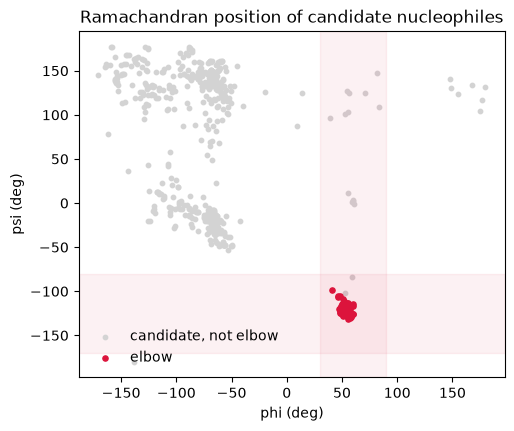

In [3]:
bg = el[~el.elbow]; fg = el[el.elbow]
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.scatter(bg.phi, bg.psi, s=10, c="lightgrey", label="candidate, not elbow")
ax.scatter(fg.phi, fg.psi, s=14, c="crimson", label="elbow")
ax.axvspan(*C.ELBOW_PHI, color="crimson", alpha=.06); ax.axhspan(*C.ELBOW_PSI, color="crimson", alpha=.06)
ax.set(xlabel="phi (deg)", ylabel="psi (deg)", title="Ramachandran position of candidate nucleophiles"); ax.legend(frameon=False)
plt.show()

## 2 · Elbow vs legacy regex

In [4]:
per = el.groupby("accession").agg(regex=("regex", "any"), elbow=("elbow", "any"), n_elbow=("elbow", "sum"),
                                  triad_elbow=("has_triad", lambda s: False))
per["triad_elbow"] = el[el.elbow].groupby("accession").has_triad.any().reindex(per.index).fillna(False)
per = per.reindex(summ.index).fillna(False).astype({"regex": bool, "elbow": bool, "triad_elbow": bool})
print(f"{n_struct} structures")
print(f"  structures with an elbow: {int(per.elbow.sum())}   (elbows per structure: {per.n_elbow.value_counts().to_dict()})")
print(f"  structures with >=1 legacy-regex hit: {int(per.regex.sum())}   total regex hits: {int(el.regex.sum())}")
print(f"  residue-level: elbow & regex = {int((el.elbow & el.regex).sum())}, elbow only = {int((el.elbow & ~el.regex).sum())}, "
      f"regex only = {int((~el.elbow & el.regex).sum())}")
print(f"  elbow residues with a Ser/Asp-His-Asp/Glu triad within cutoffs: {int((el.elbow & el.has_triad).sum())} / {int(el.elbow.sum())}")

203 structures
  structures with an elbow: 160   (elbows per structure: {1.0: 160, 0.0: 43})
  structures with >=1 legacy-regex hit: 181   total regex hits: 620
  residue-level: elbow & regex = 138, elbow only = 22, regex only = 482
  elbow residues with a Ser/Asp-His-Asp/Glu triad within cutoffs: 121 / 160


**Reading this.** The regex finds most real nucleophiles, but also many Gly-flanked Ser/Thr/Cys that are not at the elbow, so a
hit is weak evidence by itself (it only worked in the original pipeline because the triad-distance test followed it). The elbow gives
at most one call per structure. Both the elbow and its absence are interpretable (below).

### Elbows the regex does not match

In [5]:
miss = el[el.elbow & ~el.regex].copy()
miss["triad_acid"] = miss.acid_resname
display(miss[["accession", "gene", "resnum", "aa", "context", "phi", "psi", "has_triad"]].sort_values(["context", "gene"]).reset_index(drop=True))
print(miss.context.value_counts().to_dict())

,accession,gene,resnum,aa,context,phi,psi,has_triad
0,Q9H6B9,EPHX3,173,D,AHDWG,52.4,-115.7,True
1,H3BMU8,PLA2G15,218,S,AHSMG,49.4,-124.6,False
2,Q8NCC3,PLA2G15,198,S,AHSMG,50.7,-128.5,True
3,A0A1U9X777,,355,S,AWSIG,56.3,-124.2,True
4,A8K0A4,,355,S,AWSIG,56.4,-124.0,True
5,A0A0G2JJD3,ABHD16A,398,S,AWSIG,56.6,-124.8,True
6,O95870,ABHD16A,355,S,AWSIG,58.1,-126.1,True
7,B3KNX9,BAT5,136,S,AWSIG,57.3,-124.3,True
8,B4DFE9,,335,D,GHDWG,48.3,-119.1,True
9,E5RFH6,EPHX2,152,D,GHDWG,48.5,-119.6,True


{'SHDYG': 9, 'AWSIG': 5, 'GHDWG': 5, 'AHSMG': 2, 'AHDWG': 1}


**Reading this.** Two groups: (i) `AWSIG` (ABHD16A, the catalytic S355) and `AHSMG` (PLA2G15, S198) have a non-Gly residue at −2, so the
regex rejects them; (ii) `xHDxG` contexts where the nucleophile is an **Asp** (EPHX2, EPHX3, EPHX4 and relatives):
the epoxide-hydrolase mechanism uses Asp-His-Asp/Glu and the original Ser/Cys/Thr regex cannot see it.
Entries with other names in group (ii) (e.g. MEST) have not been checked against the literature.

### Structures with no elbow

In [6]:
no = per[~per.elbow].index
t = summ.loc[no].join(meta[["gene_name", "reviewed"]])
full = meta.assign(n=summ.n_residues).groupby("gene_name").n.max()
t["longest_for_gene"] = t.gene_name.map(full)
t["fraction_of_longest"] = (t.n_residues / t.longest_for_gene).round(2)
display(t.sort_values("fraction_of_longest").reset_index())
print(f"{len(no)} structures without an elbow; median length {t.n_residues.median():.0f} aa vs {summ.n_residues.median():.0f} aa overall; "
      f"{int(t.reviewed.sum())} reviewed")

,accession,n_residues,mean_plddt,gene_name,reviewed,longest_for_gene,fraction_of_longest
0,A2IBA8,33,55.6,LIPH,False,451.0,0.07
1,B9TXP1,49,89.8,,False,572.0,0.09
2,Q4JIZ7,60,94.8,,False,572.0,0.10
3,A0AAG2UW70,57,95.3,PNLIPRP2,False,469.0,0.12
4,H0YML6,40,80.7,SPG21,False,308.0,0.13
5,B4DU46,81,91.7,,False,572.0,0.14
6,F5GY58,167,64.6,DAGLA,False,1042.0,0.16
7,H0YLD7,53,77.3,SPG21,False,308.0,0.17
8,E5RHN7,105,86.9,LPL,False,475.0,0.22
9,C9JA85,149,63.4,DAGLB,False,672.0,0.22


43 structures without an elbow; median length 146 aa vs 298 aa overall; 1 reviewed


**Reading this.** Most structures without an elbow are short isoform/fragment entries (compare `n_residues` with the longest entry
for the same gene) whose truncated models lack the β5–αC region. Only one reviewed entry lacks an elbow: ABHD15 (Q6UXT9),
which is worth inspecting by hand (low-confidence model, missing/degenerate nucleophile, or the elbow thresholds are too strict).

## 3 · Elbow calls on the ProtBert map

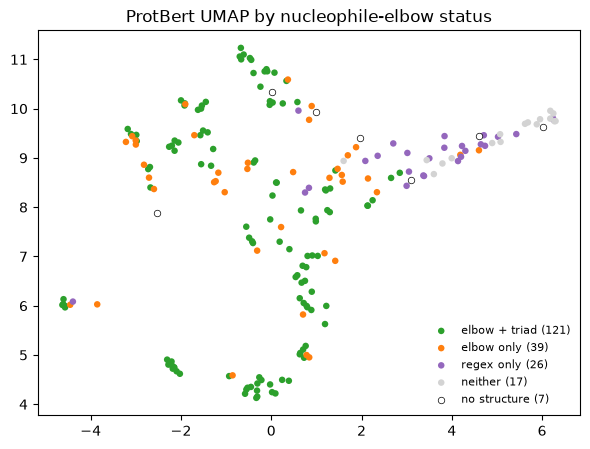

elbow + triad    121
elbow only        39
regex only        26
neither           17
no structure       7
Name: count, dtype: int64

In [7]:
accs, X = D.load_protbert(); U = D.umap_coords(X)
cat = pd.Series("no structure", index=accs)
have = [a for a in accs if a in per.index]
cat[have] = np.where(per.loc[have, "elbow"] & per.loc[have, "triad_elbow"], "elbow + triad",
             np.where(per.loc[have, "elbow"], "elbow only", np.where(per.loc[have, "regex"], "regex only", "neither")))
colours = {"elbow + triad": "tab:green", "elbow only": "tab:orange", "regex only": "tab:purple", "neither": "lightgrey", "no structure": "white"}
fig, ax = plt.subplots(figsize=(7, 5))
for k, c in colours.items():
    idx = np.where(cat.values == k)[0]
    ax.scatter(U[idx, 0], U[idx, 1], s=22, c=c, edgecolors="k" if k == "no structure" else "none", linewidths=.5, label=f"{k} ({len(idx)})")
ax.legend(frameon=False, fontsize=8); ax.set(title="ProtBert UMAP by nucleophile-elbow status"); plt.show()
cat.value_counts()